# LAB 07 · Transformer Architecture
## Từ self-attention đến phân loại cảm xúc văn bản


## 0. Môi trường và cấu hình

Yêu cầu Python 3.10+, PyTorch 2.x, NumPy, pandas, matplotlib, scikit-learn, IPython; `positional_encoding.py` nằm cùng thư mục với notebook. Dữ liệu IMDb được đọc từ `aclImdb_v1.tar.gz` theo W6, không dùng API `datasets`. Cell cài đặt được để dạng comment để không tự thay đổi môi trường.


In [25]:
# Chạy riêng cell này nếu môi trường chưa đủ thư viện, rồi restart kernel.
# %pip install torch numpy pandas matplotlib scikit-learn ipython

In [26]:
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from collections import Counter
import copy, gc, hashlib, html, itertools, json, math, random, re, time, tarfile
import platform, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
)
from IPython.display import display, Markdown

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'positional_encoding.py').exists():
    raise FileNotFoundError('Đặt positional_encoding.py cùng thư mục làm việc với notebook.')
from positional_encoding import PositionalEncoding, positional_encoding

DATA_SOURCE = 'imdb'                    # 'imdb': W6 tar.gz ở Colab; 'local_csv': 3 CSV
PROFILE = 'full'                       # 'quick': lấy mẫu sau chia W6; 'full': giữ toàn bộ
LOCAL_DATA_DIR = PROJECT_DIR / 'data'
ARTIFACT_DIR = PROJECT_DIR / 'artifacts'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
(ARTIFACT_DIR / 'checkpoints').mkdir(exist_ok=True)
(ARTIFACT_DIR / 'histories').mkdir(exist_ok=True)
PROFILES = {
    'quick': dict(n_train=3000, n_val=600, n_test=1000, epochs=3, seeds=[42]),
    'full': dict(n_train=None, n_val=None, n_test=None, epochs=8, seeds=[42, 52, 62]),
}
CFG = dict(PROFILES[PROFILE])
D_MODEL, D_FF, N_LAYERS = 128, 256, 1
BATCH_SIZE, LEARNING_RATE, WEIGHT_DECAY = 32, 1e-3, 1e-4
DROPOUT, MAX_VOCAB, MIN_FREQ = 0.1, 20000, 2
BASE_HEADS, BASE_LENGTH = 4, 128
SPLIT_SEED = 42                        # seed chia dữ liệu như W6
SEEDS = list(CFG['seeds'])
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEEDS[0])
ENVIRONMENT = dict(python=platform.python_version(), torch=torch.__version__,
                   numpy=np.__version__, pandas=pd.__version__, device=str(DEVICE),
                   cuda=torch.version.cuda, profile=PROFILE, data_source=DATA_SOURCE)
print(json.dumps(ENVIRONMENT, indent=2, ensure_ascii=False))
print('Run config:', CFG)
print('F1 = macro; positive class = 1. CUDA có thể còn sai khác nhỏ giữa thiết bị.')

{
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "device": "cuda",
  "cuda": "13.0",
  "profile": "full",
  "data_source": "imdb"
}
Run config: {'n_train': None, 'n_val': None, 'n_test': None, 'epochs': 8, 'seeds': [42, 52, 62]}
F1 = macro; positive class = 1. CUDA có thể còn sai khác nhỏ giữa thiết bị.


In [27]:
# Bộ số MINH HỌA, không phải số liệu được W7.pdf cho sẵn.
X_demo = torch.tensor([[1., 0., 1., 0.], [0., 1., 0., 1.], [1., 1., 0., 0.]])
WQ_demo = torch.tensor([[1., 0.], [0., 1.], [1., 0.], [0., 1.]])
WK_demo = torch.tensor([[0., 1.], [1., 0.], [0., 1.], [1., 0.]])
WV_demo = torch.tensor([[1., 0.], [0., 1.], [0., 0.], [1., 1.]])
Q_demo, K_demo, V_demo = X_demo @ WQ_demo, X_demo @ WK_demo, X_demo @ WV_demo
S_demo = (Q_demo @ K_demo.T) / math.sqrt(2)
A_demo = S_demo.softmax(dim=-1)
Z_demo = A_demo @ V_demo
for name in ['Q_demo', 'K_demo', 'V_demo', 'S_demo', 'A_demo', 'Z_demo']:
    print(name, '\n', globals()[name].numpy().round(5))
assert torch.allclose(A_demo.sum(-1), torch.ones(3))


Q_demo 
 [[2. 0.]
 [0. 2.]
 [1. 1.]]
K_demo 
 [[0. 2.]
 [2. 0.]
 [1. 1.]]
V_demo 
 [[1. 0.]
 [1. 2.]
 [1. 1.]]
S_demo 
 [[0.      2.82843 1.41421]
 [2.82843 0.      1.41421]
 [1.41421 1.41421 1.41421]]
A_demo 
 [[0.04539 0.76792 0.18669]
 [0.76792 0.04539 0.18669]
 [0.33333 0.33333 0.33333]]
Z_demo 
 [[1.      1.72253]
 [1.      0.27747]
 [1.      1.     ]]


In [28]:
pe_small = positional_encoding(3, 4, dtype=torch.float64)
display(pd.DataFrame(pe_small.numpy(), index=pd.Index(range(3), name='position'),
                     columns=[f'dim_{i}' for i in range(4)]))
# Đối chiếu độc lập bằng công thức vô hướng, kể cả d_model lẻ.
for width in (1, 4, 5, 128):
    table = positional_encoding(7, width, dtype=torch.float64)
    for pos in range(7):
        for j in range(width):
            angle = pos / (10000.0 ** (2 * (j // 2) / width))
            expected = math.sin(angle) if j % 2 == 0 else math.cos(angle)
            assert abs(table[pos, j].item() - expected) < 1e-12
print('PE khớp công thức vô hướng; đã kiểm tra cả d_model lẻ.')


,dim_0,dim_1,dim_2,dim_3
position,,,,
0,0.000000,1.000000,0.000000,1.00000
1,0.841471,0.540302,0.010000,0.99995
2,0.909297,-0.416147,0.019999,0.99980


PE khớp công thức vô hướng; đã kiểm tra cả d_model lẻ.


## 11–12. Experiment 1 – positional encoding và permutation

**Mục tiêu:** so sánh embedding, input có PE và self-attention của hai thứ tự token. Hai cặp bắt buộc: `I love NLP` ↔ `NLP love I` và `dog bites man` ↔ `man bites dog`.

**Protocol:** cùng embedding và cùng trọng số attention, `eval()` tắt dropout. Báo cáo cả output theo vị trí, output sau căn chỉnh lại token và masked mean của chuỗi. Ở đây chưa huấn luyện: đây là kiểm tra tính chất kiến trúc, chưa chứng minh chất lượng phân loại.

Phần thực thi permutation nằm ngay sau định nghĩa core ở mục 17 để không lặp một bản attention khác.


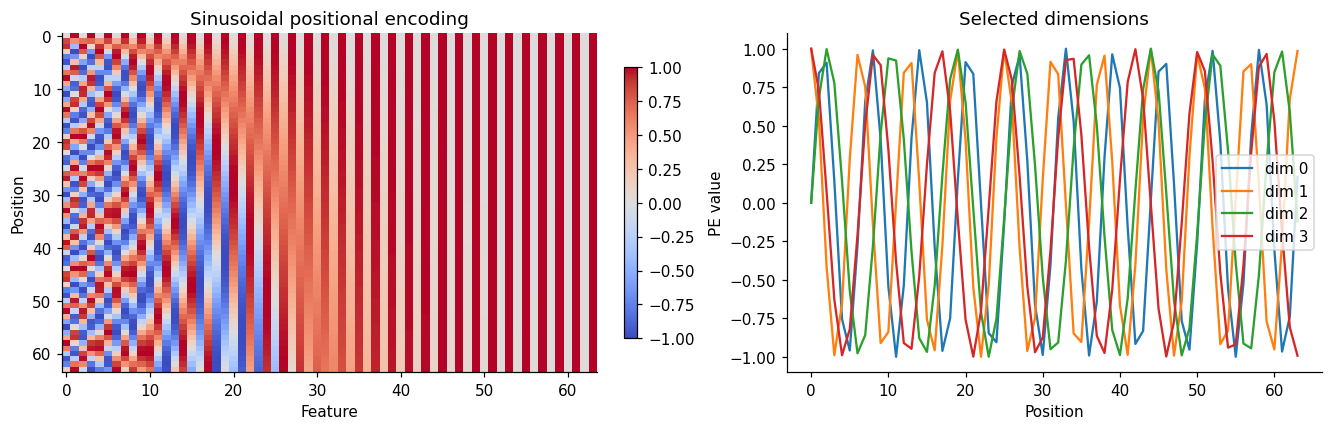

In [29]:
pe_plot = positional_encoding(64, 64).numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
im = axes[0].imshow(pe_plot, aspect='auto', cmap='coolwarm', vmin=-1, vmax=1)
axes[0].set(xlabel='Feature', ylabel='Position', title='Sinusoidal positional encoding')
fig.colorbar(im, ax=axes[0], shrink=.8)
for j in [0, 1, 2, 3]:
    axes[1].plot(pe_plot[:, j], label=f'dim {j}')
axes[1].set(xlabel='Position', ylabel='PE value', title='Selected dimensions')
axes[1].legend()
fig.savefig(ARTIFACT_DIR / 'positional_encoding.png', dpi=180)
plt.show()


In [30]:
x_ffn = torch.tensor([1., 2.])
W1, b1 = torch.eye(2), torch.tensor([0., -1.])
h_ffn = torch.relu(W1 @ x_ffn + b1)
print('h kiểm tra =', h_ffn)
W2, b2 = None, None  # Thay bằng dữ kiện bổ sung nếu có.
if W2 is not None and b2 is not None:
    print('y kiểm tra =', W2 @ h_ffn + b2)
else:
    print('Chưa có W2, b2: ghi y = W2 @ h + b2 trong phần tự trả lời.')


h kiểm tra = tensor([1., 1.])
Chưa có W2, b2: ghi y = W2 @ h + b2 trong phần tự trả lời.


## 15–16. Residual connection và LayerNorm

Core dùng post-norm theo sơ đồ đề: $H=LN_1(X+Dropout(MHA(X)))$, rồi $Y=LN_2(H+Dropout(FFN(H)))$.


## 17. Core implementation – Transformer Encoder block

Quy ước xuyên suốt: `valid_mask[b,t]=True` là token hợp lệ. Mask chặn **key padding**, đồng thời đặt output/attention của **query padding** về 0. Không dùng causal mask cho encoder phân loại. Không chấp nhận một mẫu có toàn padding.


In [31]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        if d_model <= 0 or n_heads <= 0 or d_model % n_heads:
            raise ValueError('d_model phải chia hết cho n_heads và cả hai phải dương.')
        self.d_model, self.n_heads = d_model, n_heads
        self.d_k = d_model // n_heads
        self.q_proj, self.k_proj, self.v_proj = [nn.Linear(d_model, d_model) for _ in range(3)]
        self.out_proj = nn.Linear(d_model, d_model)
        self.attn_dropout = nn.Dropout(dropout)

    def forward(self, x, valid_mask=None, return_attention=False):
        B, T, D = x.shape
        if D != self.d_model:
            raise ValueError('Feature dimension không khớp d_model.')
        if valid_mask is None:
            valid_mask = torch.ones(B, T, dtype=torch.bool, device=x.device)
        if valid_mask.shape != (B, T) or valid_mask.dtype != torch.bool:
            raise ValueError('valid_mask phải là bool tensor (B,T).')
        if T == 0 or not valid_mask.any(dim=1).all():
            raise ValueError('Mỗi mẫu phải có ít nhất một token hợp lệ.')
        def split_heads(projection):
            return projection(x).reshape(B, T, self.n_heads, self.d_k).transpose(1, 2)
        q, k, v = [split_heads(p) for p in (self.q_proj, self.k_proj, self.v_proj)]
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_k)
        scores = scores.masked_fill(~valid_mask[:, None, None, :], float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = self.attn_dropout(weights) @ v
        context = context.transpose(1, 2).contiguous().reshape(B, T, D)
        output = self.out_proj(context).masked_fill(~valid_mask[..., None], 0.)
        if return_attention:
            # Trả weights trước dropout để plot/phân tích trong eval mode.
            weights = weights.masked_fill(~valid_mask[:, None, :, None], 0.)
            return output, weights
        return output, None


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadSelfAttention(d_model, n_heads, dropout)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.dropout1, self.dropout2 = nn.Dropout(dropout), nn.Dropout(dropout)

    def forward(self, x, valid_mask=None, return_attention=False):
        a, weights = self.attention(x, valid_mask, return_attention)
        x = self.norm1(x + self.dropout1(a))
        x = self.norm2(x + self.dropout2(self.ffn(x)))
        if valid_mask is not None:
            x = x.masked_fill(~valid_mask[..., None], 0.)
        return x, weights


### Chạy Experiment 1 / permutation của mục 11–12

`raw_token_maxdiff` so sánh theo vị trí hiện tại; `aligned_token_maxdiff` đưa token về cùng thứ tự trước khi so sánh. `mean_pool_l2` đo khoảng cách representation toàn câu. Không suy từ khác biệt theo vị trí rằng model đã hiểu thứ tự.


In [32]:
seed_everything(123)
toy_vocab = {w: i for i, w in enumerate(['I', 'love', 'NLP', 'dog', 'bites', 'man'])}
toy_embedding = nn.Embedding(len(toy_vocab), 16).eval()
toy_attention = MultiHeadSelfAttention(16, 4, dropout=0.).eval()
toy_pe = PositionalEncoding(16, max_len=3).eval()
permutation_rows = []
with torch.no_grad():
    for sentence in [('I', 'love', 'NLP'), ('dog', 'bites', 'man')]:
        ids = torch.tensor([[toy_vocab[w] for w in sentence]])
        permutation = torch.tensor([2, 1, 0])
        a, b = toy_embedding(ids), toy_embedding(ids[:, permutation])
        for use_pe in (False, True):
            a_in, b_in = (toy_pe(a), toy_pe(b)) if use_pe else (a, b)
            ya, _ = toy_attention(a_in)
            yb, _ = toy_attention(b_in)
            row = dict(sentence=' '.join(sentence), reordered=' '.join(sentence[i] for i in permutation),
                       positional_encoding=use_pe,
                       raw_token_maxdiff=(ya-yb).abs().max().item(),
                       aligned_token_maxdiff=(ya-yb[:, permutation.argsort()]).abs().max().item(),
                       mean_pool_l2=torch.linalg.vector_norm(ya.mean(1)-yb.mean(1)).item())
            permutation_rows.append(row)
            if not use_pe:
                assert row['aligned_token_maxdiff'] < 1e-5
                assert row['mean_pool_l2'] < 1e-5
    display(pd.DataFrame(a[0].numpy(), index=sentence).round(3))
    display(pd.DataFrame(toy_pe(a)[0].numpy(), index=sentence).round(3))
permutation_results = pd.DataFrame(permutation_rows)
permutation_results.to_csv(ARTIFACT_DIR / 'permutation_results.csv', index=False)
display(permutation_results)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
dog,0.877,1.622,-1.478,1.133,-1.220,1.314,1.053,0.139,2.247,-0.804,-0.281,0.770,-0.660,-0.798,0.184,0.229
bites,0.515,0.994,-0.259,-1.083,-0.044,1.624,-2.323,1.088,0.672,0.693,-0.949,-0.077,-0.153,0.117,0.440,-1.447
man,0.255,-0.550,1.004,0.827,-0.395,0.489,-0.217,-1.747,-1.603,-1.076,0.903,-0.722,-0.595,-0.711,0.623,-1.373


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
dog,0.877,2.622,-1.478,2.133,-1.220,2.314,1.053,1.139,2.247,0.196,-0.281,1.770,-0.660,0.202,0.184,1.229
bites,1.356,1.534,0.052,-0.132,0.055,2.619,-2.291,2.087,0.682,1.693,-0.946,0.923,-0.152,1.117,0.441,-0.447
man,1.165,-0.966,1.595,1.634,-0.196,1.469,-0.154,-0.749,-1.583,-0.077,0.909,0.278,-0.593,0.289,0.624,-0.373


,sentence,reordered,positional_encoding,raw_token_maxdiff,aligned_token_maxdiff,mean_pool_l2
0,I love NLP,NLP love I,False,0.096114,6.705523e-08,9.599402e-08
1,I love NLP,NLP love I,True,0.141714,1.035973e-01,8.951221e-02
2,dog bites man,man bites dog,False,0.332313,5.960464e-08,5.424105e-08
3,dog bites man,man bites dog,True,0.330620,1.202967e-01,1.126222e-01


### Kết quả và trả lời câu hỏi — Experiment 1: Positional Encoding / Permutation

**Câu hỏi: Nếu chỉ dùng self-attention và không có positional information, tại sao thứ tự token trở thành vấn đề?**

Output thực nghiệm với cùng embedding và trọng số self-attention cho thấy:

| Cặp câu bị đảo thứ tự | Positional Encoding | `aligned_token_maxdiff` | `mean_pool_l2` |
|---|:---:|---:|---:|
| `I love NLP` / `NLP love I` | Không | $6.71\times10^{-8}$ | $9.60\times10^{-8}$ |
| `I love NLP` / `NLP love I` | Có | 0.1036 | 0.0895 |
| `dog bites man` / `man bites dog` | Không | $5.96\times10^{-8}$ | $5.42\times10^{-8}$ |
| `dog bites man` / `man bites dog` | Có | 0.1203 | 0.1126 |

Khi **không có PE**, sau khi căn chỉnh các token về cùng thứ tự, sai khác gần như bằng 0 (chỉ còn sai số số học); mean pooling cũng hầu như không đổi. Self-attention không có thông tin vị trí là **permutation-equivariant**: đảo token chỉ dẫn đến đảo tương ứng các hàng output; với mean pooling (permutation-invariant), hai câu hoán vị cho cùng biểu diễn toàn câu. Vì thế mô hình khó nhận ra sự đảo vai trò như `dog bites man` và `man bites dog` nếu không có nguồn thông tin thứ tự nào khác.

Khi **có PE**, sai khác sau căn chỉnh và sai khác mean pooling đều lớn hơn 0 trong cả hai cặp, chứng tỏ biểu diễn phụ thuộc vị trí. Chú ý: `raw_token_maxdiff` khác 0 ngay cả khi không có PE vì phép so sánh theo **vị trí chưa căn chỉnh**; chỉ số này riêng lẻ không chứng minh nhận biết thứ tự. Đây là thí nghiệm **toy chưa huấn luyện**, không phải số đo độ chính xác phân loại.


## Kiểm thử runtime shapes và Transformer block

Chạy các kiểm tra về tensor dimensions, padding mask, output và gradient. Phần tính toán thủ công được trình bày trong `calculations.md`.

In [33]:
shape_block = TransformerBlock(128, 4, 256, dropout=0.).eval()
shape_x = torch.randn(8, 100, 128)
shape_mask = torch.ones(8, 100, dtype=torch.bool)
with torch.no_grad():
    q = shape_block.attention.q_proj(shape_x).reshape(8, 100, 4, 32).transpose(1, 2)
    y, attn = shape_block(shape_x, shape_mask, return_attention=True)
    runtime_shapes = {
        'X': tuple(shape_x.shape), 'Q / K / V (split heads)': tuple(q.shape),
        'scores / weights': tuple(attn.shape), 'context per head': tuple(q.shape),
        'concat / projected attention': tuple(shape_x.shape),
        'FFN hidden': tuple(shape_block.ffn[0](shape_x).shape),
        'FFN output / block output': tuple(y.shape),
    }
display(pd.DataFrame(runtime_shapes.items(), columns=['tensor', 'runtime_shape']))
assert y.shape == shape_x.shape and torch.isfinite(y).all()
assert torch.allclose(attn.sum(-1), torch.ones(8, 4, 100), atol=1e-6)

# Padding invariance và gradient: vị trí pad không ảnh hưởng token thật.
probe = torch.randn(2, 5, 128, requires_grad=True)
mask = torch.tensor([[1, 1, 1, 0, 0], [1, 1, 1, 1, 1]], dtype=torch.bool)
out, weights = shape_block(probe, mask, True)
altered = probe.detach().clone()
altered[~mask] = 999.
with torch.no_grad():
    out_altered, _ = shape_block(altered, mask)
assert torch.allclose(out[mask], out_altered[mask], atol=1e-5)
assert weights[0, :, :, 3:].abs().max() == 0
assert out[~mask].abs().max() == 0
out.square().mean().backward()
assert probe.grad is not None and torch.isfinite(probe.grad).all()
print('Core: shape, key/query padding, backward đều hợp lệ.')


,tensor,runtime_shape
0,X,"(8, 100, 128)"
1,Q / K / V (split heads),"(8, 4, 100, 32)"
2,scores / weights,"(8, 4, 100, 100)"
3,context per head,"(8, 4, 100, 32)"
4,concat / projected attention,"(8, 100, 128)"
5,FFN hidden,"(8, 100, 256)"
6,FFN output / block output,"(8, 100, 128)"


Core: shape, key/query padding, backward đều hợp lệ.


## Chuẩn bị dữ liệu IMDb và chia tập theo W6

Đọc dữ liệu **giống `self_attention(4).ipynb` (LAB 06)**:

- Trên **Google Colab**, đặt `aclImdb_v1.tar.gz` ở `/content/`. Nếu bốn thư mục chưa đủ **12.500 review/thư mục**, giải nén vào `/content/w4` bằng `tarfile` (không dùng Hugging Face `datasets`).
- Đọc tất cả review từ `train/neg`, `train/pos`, `test/neg`, `test/pos`, **gộp thành 50.000 review**, gán nhãn `neg=0`, `pos=1`.
- Giống W6, tạo `group` bằng **MD5 của văn bản sau `clean_text` W6**; chia **group-aware** với `train_test_split`: 70% nhóm train, 15% validation, 15% test; `random_state=42`, stratify nhãn nhóm. Cách này khác với việc giữ test chính thức của IMDb.
- `PROFILE='full'` dùng toàn bộ ba tập sau chia; `PROFILE='quick'` **lấy mẫu stratify sau khi chia** để thử nhanh. Do đó ở chế độ `quick`, số mẫu báo cáo nhỏ hơn W6 đầy đủ nhưng các nhóm không bị chia chéo.
- Các experiment W7 dùng chung một lần chia; vocabulary chỉ học trên train. Phần tokenization và Transformer của W7 **không đổi**.
- `DATA_SOURCE='local_csv'` vẫn được giữ như phương án phụ nếu đã chuẩn bị các CSV, nhưng không phải quy trình IMDb W6.


In [34]:
LABEL_NAMES = ['negative', 'positive']
IMDB_ARCHIVE = Path('/content/aclImdb_v1.tar.gz')
IMDB_ROOT = Path('/content/w4/aclImdb')


def normalize_frame(frame, split_name):
    """Kiểm tra schema của tập CSV; tập IMDb W6 được dựng trực tiếp."""
    frame = frame.copy()
    if not {'text', 'label'}.issubset(frame.columns):
        raise ValueError(f'{split_name}: cần cột text,label.')
    if frame[['text', 'label']].isna().any().any():
        raise ValueError(f'{split_name}: có text/label bị thiếu.')
    label_map = {'0': 0, '1': 1, 'negative': 0, 'positive': 1, 'neg': 0, 'pos': 1}
    frame['label'] = frame['label'].astype(str).str.lower().str.strip().map(label_map)
    if frame['label'].isna().any():
        raise ValueError('Nhãn phải là 0/1 hoặc negative/positive (neg/pos).')
    frame['label'] = frame['label'].astype(int)
    frame['text'] = frame['text'].astype(str)
    if frame['text'].str.strip().eq('').any():
        raise ValueError(f'{split_name}: văn bản rỗng; hãy xử lý rõ ràng trước khi chạy.')
    if 'source_id' not in frame:
        frame['source_id'] = [f'{split_name}:{i}' for i in range(len(frame))]
    return frame[['source_id', 'text', 'label']].reset_index(drop=True)


def w6_tokenizer(text):
    # Giữ nguyên bước clean_text dùng để nhóm văn bản ở LAB 06.
    text = re.sub(r'<br\s*/?>', ' ', str(text).lower())
    return re.findall(r'[a-z0-9]+', text)


def w6_clean_text(text):
    return ' '.join(w6_tokenizer(text))


def imdb_folder_counts(root=IMDB_ROOT):
    return [len(list((root / split / folder).glob('*.txt')))
            for split in ['train', 'test'] for folder in ['neg', 'pos']]


def load_imdb_like_w6(archive=IMDB_ARCHIVE, root=IMDB_ROOT, expected_per_folder=12500):
    """Đọc bốn folder IMDb đúng pipeline file nén/đường dẫn LAB 06."""
    counts = imdb_folder_counts(root)
    if counts != [expected_per_folder] * 4:
        if not archive.exists():
            raise FileNotFoundError(
                f'Không tìm thấy {archive}; upload aclImdb_v1.tar.gz vào /content/ như W6. '
                f'Số file hiện tại (train/neg, train/pos, test/neg, test/pos): {counts}')
        root.parent.mkdir(parents=True, exist_ok=True)
        with tarfile.open(archive, 'r:gz') as tar:
            tar.extractall(root.parent, filter='data')
        counts = imdb_folder_counts(root)
    if counts != [expected_per_folder] * 4:
        raise ValueError(f'IMDb chưa đủ 4 folder (mỗi folder {expected_per_folder}): {counts}')

    def load_data(split):
        texts, labels, source_ids = [], [], []
        for label, folder in [(0, 'neg'), (1, 'pos')]:
            for file in sorted((root / split / folder).glob('*.txt')):
                texts.append(file.read_text(encoding='utf-8'))
                labels.append(label)
                source_ids.append(f'{split}/{folder}/{file.name}')
        return texts, labels, source_ids

    x_train_old, y_train_old, id_train_old = load_data('train')
    x_test_old, y_test_old, id_test_old = load_data('test')
    data = pd.DataFrame({
        'source_id': id_train_old + id_test_old,
        'text': x_train_old + x_test_old,
        'label': y_train_old + y_test_old,
    })
    if len(data) != 4 * expected_per_folder:
        raise ValueError(f'Không đủ review IMDb: {len(data)}')
    data['group'] = data['text'].map(
        lambda s: hashlib.md5(w6_clean_text(s).encode('utf-8')).hexdigest())
    display(pd.DataFrame({
        'Tập gốc': ['train/neg', 'train/pos', 'test/neg', 'test/pos'],
        'Số review': counts,
    }))
    return data


def split_imdb_groups_like_w6(data, seed=SPLIT_SEED):
    """Tách 70/15/15 THEO NHÓM bằng đúng 2 lượt train_test_split W6."""
    group_labels = data.groupby('group')['label'].first()
    train_groups, other_groups = train_test_split(
        group_labels.index.to_numpy(), test_size=0.3,
        random_state=seed, stratify=group_labels.to_numpy())
    val_groups, test_groups = train_test_split(
        other_groups, test_size=0.5,
        random_state=seed, stratify=group_labels.loc[other_groups].to_numpy())
    train = data[data.group.isin(train_groups)].reset_index(drop=True)
    val = data[data.group.isin(val_groups)].reset_index(drop=True)
    test = data[data.group.isin(test_groups)].reset_index(drop=True)
    assert len(train) + len(val) + len(test) == len(data)
    assert not (set(train.group) & set(val.group))
    assert not (set(train.group) & set(test.group))
    assert not (set(val.group) & set(test.group))
    return train, val, test


def load_raw_splits():
    if DATA_SOURCE == 'imdb':
        data = load_imdb_like_w6()
        return split_imdb_groups_like_w6(data)
    if DATA_SOURCE == 'local_csv':
        train = normalize_frame(pd.read_csv(LOCAL_DATA_DIR / 'train.csv'), 'local_train')
        test = normalize_frame(pd.read_csv(LOCAL_DATA_DIR / 'test.csv'), 'local_test')
        val_path = LOCAL_DATA_DIR / 'validation.csv'
        if val_path.exists():
            val = normalize_frame(pd.read_csv(val_path), 'local_validation')
        else:
            train, val = train_test_split(train, test_size=.2, stratify=train.label,
                                         random_state=SPLIT_SEED)
        return train, val, test
    raise ValueError('DATA_SOURCE phải là imdb hoặc local_csv.')


def cap_stratified(frame, limit):
    if limit is not None and len(frame) > limit:
        frame, _ = train_test_split(frame, train_size=limit, stratify=frame.label,
                                    random_state=SPLIT_SEED)
    frame = frame.reset_index(drop=True)
    if set(frame.label.unique()) != {0, 1}:
        raise ValueError('Mỗi split phải có đủ hai lớp để đánh giá nhị phân.')
    return frame


train_df, val_df, test_df = load_raw_splits()
train_df = cap_stratified(train_df, CFG['n_train'])
val_df = cap_stratified(val_df, CFG['n_val'])
test_df = cap_stratified(test_df, CFG['n_test'])
for name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    print(name, len(frame), frame.label.value_counts().sort_index().to_dict())

manifest = pd.concat([
    frame[['source_id', 'label']].assign(
        split=name,
        group=(frame['group'] if 'group' in frame else
               frame.text.map(lambda t: hashlib.md5(w6_clean_text(t).encode()).hexdigest())),
        text_sha256=[hashlib.sha256(t.encode()).hexdigest() for t in frame.text],
    )
    for name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]
], ignore_index=True)
manifest.to_csv(ARTIFACT_DIR / 'split_manifest.csv', index=False)
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    a = set(manifest.loc[manifest.split == left, 'group'])
    b = set(manifest.loc[manifest.split == right, 'group'])
    overlap = a & b
    if DATA_SOURCE == 'imdb':
        assert not overlap, f'Trùng group giữa {left}/{right}: {len(overlap)}'
    elif overlap:
        print(f'Lưu ý dữ liệu CSV: {len(overlap)} nhóm văn bản trùng giữa {left}/{right}.')
print('Split W6: group-aware 70/15/15, random_state=42 | Profile:', PROFILE)

,Tập gốc,Số review
0,train/neg,12500
1,train/pos,12500
2,test/neg,12500
3,test/pos,12500


train 34999 {0: 17502, 1: 17497}
validation 7499 {0: 3745, 1: 3754}
test 7502 {0: 3753, 1: 3749}
Split W6: group-aware 70/15/15, random_state=42 | Profile: full


In [35]:
PAD_ID, UNK_ID, CLS_ID = 0, 1, 2


def tokenize(text):
    cleaned = html.unescape(re.sub(r'<[^>]+>', ' ', str(text)))
    return re.findall(r"\w+(?:'\w+)?|[^\w\s]", cleaned.lower().replace('’', "'"))


counts = Counter(token for text in train_df.text for token in tokenize(text))
vocab = {'[PAD]': PAD_ID, '[UNK]': UNK_ID, '[CLS]': CLS_ID}
for token, count in counts.most_common():
    if count >= MIN_FREQ and token not in vocab and len(vocab) < MAX_VOCAB:
        vocab[token] = len(vocab)
id_to_token = {idx: token for token, idx in vocab.items()}
(ARTIFACT_DIR / 'vocab.json').write_text(json.dumps(vocab, ensure_ascii=False), encoding='utf-8')


def encode_frame(frame):
    items = []
    for row in frame.itertuples(index=False):
        ids = [vocab.get(token, UNK_ID) for token in tokenize(row.text)]
        items.append(dict(ids=ids or [UNK_ID], token_count=len(ids),
                          label=int(row.label), source_id=row.source_id))
    return items


train_items, val_items, test_items = [encode_frame(f) for f in [train_df, val_df, test_df]]


class ReviewDataset(Dataset):
    def __init__(self, items, max_length):
        if max_length < 2:
            raise ValueError('max_length >= 2: một CLS và ít nhất một content token.')
        self.items, self.max_length = items, max_length
    def __len__(self):
        return len(self.items)
    def __getitem__(self, index):
        item = self.items[index]
        ids = [CLS_ID] + item['ids'][:self.max_length - 1]
        # Pad tới đúng max_length để phép so sánh chi phí theo length rõ ràng.
        padded = ids + [PAD_ID] * (self.max_length - len(ids))
        return torch.tensor(padded, dtype=torch.long), torch.tensor(item['label'], dtype=torch.long)


def make_loader(items, max_length, shuffle=False, seed=42):
    return DataLoader(ReviewDataset(items, max_length), batch_size=BATCH_SIZE,
                      shuffle=shuffle, num_workers=0,
                      generator=torch.Generator().manual_seed(seed),
                      pin_memory=(DEVICE.type == 'cuda'))


summary = []
for name, items in [('train', train_items), ('validation', val_items), ('test', test_items)]:
    lengths = np.array([x['token_count'] for x in items])
    total = sum(len(x['ids']) for x in items)
    unk = sum(x['ids'].count(UNK_ID) for x in items)
    summary.append(dict(split=name, samples=len(items), mean_tokens=lengths.mean(),
                        median_tokens=np.median(lengths), p95_tokens=np.quantile(lengths, .95),
                        unknown_rate=unk/max(total, 1)))
display(pd.DataFrame(summary))
print('Vocabulary chỉ fit trên train:', len(vocab))
print('max_length bao gồm CLS. Cả mean và CLS-style đều nhận cùng CLS + content.')


,split,samples,mean_tokens,median_tokens,p95_tokens,unknown_rate
0,train,34999,266.732678,200.0,684.00,0.023960
1,validation,7499,266.417922,201.0,675.00,0.025629
2,test,7502,268.103572,202.0,670.95,0.025760


Vocabulary chỉ fit trên train: 20000
max_length bao gồm CLS. Cả mean và CLS-style đều nhận cùng CLS + content.


In [36]:
def masked_mean(hidden, content_mask):
    weights = content_mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden * weights).sum(1) / weights.sum(1).clamp_min(1.)


class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, n_heads=4, max_length=128, pooling='mean', use_pe=True):
        super().__init__()
        if pooling not in ('mean', 'cls'):
            raise ValueError('pooling phải là mean hoặc cls.')
        self.embedding = nn.Embedding(vocab_size, D_MODEL, padding_idx=PAD_ID)
        self.position = PositionalEncoding(D_MODEL, dropout=0., max_len=max_length)
        self.embedding_dropout = nn.Dropout(DROPOUT)
        self.blocks = nn.ModuleList([
            TransformerBlock(D_MODEL, n_heads, D_FF, DROPOUT) for _ in range(N_LAYERS)
        ])
        self.classifier = nn.Linear(D_MODEL, 2)
        self.pooling, self.use_pe = pooling, use_pe

    def forward(self, input_ids, return_attention=False):
        valid = input_ids.ne(PAD_ID)
        if not valid.any(1).all():
            raise ValueError('Không chấp nhận input toàn padding.')
        hidden = self.embedding(input_ids)
        if self.use_pe:
            hidden = self.position(hidden)
        hidden = self.embedding_dropout(hidden).masked_fill(~valid[..., None], 0.)
        attentions = []
        for block in self.blocks:
            hidden, weights = block(hidden, valid, return_attention)
            if return_attention:
                attentions.append(weights)
        if self.pooling == 'mean':
            representation = masked_mean(hidden, valid & input_ids.ne(CLS_ID))
        else:
            if not input_ids[:, 0].eq(CLS_ID).all():
                raise ValueError('CLS-style yêu cầu CLS ở vị trí đầu.')
            representation = hidden[:, 0]
        return self.classifier(representation), attentions


class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, D_MODEL, padding_idx=PAD_ID)
        self.embedding_dropout = nn.Dropout(DROPOUT)
        self.lstm = nn.LSTM(D_MODEL, D_MODEL, num_layers=1, batch_first=True)
        self.output_dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(D_MODEL, 2)

    def forward(self, input_ids, return_attention=False):
        lengths = input_ids.ne(PAD_ID).sum(1).cpu()
        if (lengths == 0).any():
            raise ValueError('Không chấp nhận input toàn padding.')
        embeddings = self.embedding_dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(embeddings, lengths, batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        return self.classifier(self.output_dropout(hidden[-1])), []


@dataclass(frozen=True)
class ExperimentSpec:
    model_type: str = 'transformer'
    n_heads: int = BASE_HEADS
    max_length: int = BASE_LENGTH
    pooling: str = 'mean'
    use_pe: bool = True
    seed: int = 42


def build_model(spec):
    if spec.model_type == 'lstm':
        return LSTMClassifier(len(vocab))
    if spec.model_type != 'transformer':
        raise ValueError(spec.model_type)
    return TransformerClassifier(len(vocab), spec.n_heads, spec.max_length, spec.pooling, spec.use_pe)


def classification_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], average='macro', zero_division=0)
    return dict(accuracy=accuracy_score(y_true, y_pred), precision_macro=p,
                recall_macro=r, f1_macro=f,
                f1_positive=f1_score(y_true, y_pred, pos_label=1, zero_division=0))


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    losses, labels, predictions, probabilities = [], [], [], []
    total_loss, n = 0., 0
    for ids, y in loader:
        ids, y = ids.to(DEVICE), y.to(DEVICE)
        logits, _ = model(ids)
        loss = nn.functional.cross_entropy(logits, y, reduction='sum')
        total_loss += loss.item()
        n += y.numel()
        probs = logits.softmax(-1)
        labels.extend(y.cpu().tolist())
        predictions.extend(probs.argmax(-1).cpu().tolist())
        probabilities.extend(probs[:, 1].cpu().tolist())
    return dict(loss=total_loss/n, **classification_metrics(labels, predictions)), pd.DataFrame(
        dict(y_true=labels, y_pred=predictions, p_positive=probabilities))


def sync_device():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()


RUN_REGISTRY = {}
RUN_RECORDS = []
BASE_SPEC = ExperimentSpec(seed=SEEDS[0])


def run_experiment(spec):
    # Tái sử dụng cùng một run trong phiên cho các bảng có cùng cấu hình.
    # Restart & Run All sẽ huấn luyện mới, không tự dùng checkpoint cũ.
    if spec in RUN_REGISTRY:
        return RUN_REGISTRY[spec]
    seed_everything(spec.seed)
    run_id = (f'{spec.model_type}_h{spec.n_heads}_l{spec.max_length}_{spec.pooling}'
              f'_pe{int(spec.use_pe)}_s{spec.seed}')
    train_loader = make_loader(train_items, spec.max_length, True, spec.seed)
    val_loader = make_loader(val_items, spec.max_length)
    model = build_model(spec).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    history, best_loss, best_state, best_epoch = [], float('inf'), None, None
    if DEVICE.type == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    sync_device()
    start_fit = time.perf_counter()
    for epoch in range(1, CFG['epochs'] + 1):
        model.train()
        loss_sum, n = 0., 0
        sync_device()
        start_train = time.perf_counter()
        for ids, y in train_loader:
            ids, y = ids.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits, _ = model(ids)
            loss = nn.functional.cross_entropy(logits, y)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Loss không hữu hạn tại {run_id}, epoch {epoch}.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            loss_sum += loss.item() * y.numel()
            n += y.numel()
        sync_device()
        train_seconds = time.perf_counter() - start_train
        val_metrics, _ = evaluate(model, val_loader)
        history.append(dict(epoch=epoch, train_loss=loss_sum/n, train_seconds=train_seconds,
                            **{f'val_{k}': v for k, v in val_metrics.items()}))
        if val_metrics['loss'] < best_loss:
            best_loss, best_epoch = val_metrics['loss'], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"{run_id} | epoch {epoch}/{CFG['epochs']} | train={loss_sum/n:.4f} "
              f"val={val_metrics['loss']:.4f} F1={val_metrics['f1_macro']:.4f}")
    sync_device()
    fit_seconds = time.perf_counter() - start_fit
    peak_cuda_mib = torch.cuda.max_memory_allocated()/2**20 if DEVICE.type == 'cuda' else np.nan
    model.load_state_dict(best_state)
    best_metrics, _ = evaluate(model, val_loader)
    checkpoint_path = ARTIFACT_DIR / 'checkpoints' / f'{run_id}.pt'
    torch.save(best_state, checkpoint_path)  # state_dict only; không lưu đối tượng model.
    history_df = pd.DataFrame(history)
    history_df.to_csv(ARTIFACT_DIR / 'histories' / f'{run_id}.csv', index=False)
    record = dict(run_id=run_id, **asdict(spec), split='validation', profile=PROFILE,
                  data_source=DATA_SOURCE, n_train=len(train_items), n_validation=len(val_items),
                  parameters=parameter_count, fit_seconds=fit_seconds,
                  train_seconds=history_df.train_seconds.sum(), best_epoch=best_epoch,
                  peak_cuda_mib=peak_cuda_mib, checkpoint=str(checkpoint_path), **best_metrics)
    RUN_REGISTRY[spec] = record
    RUN_RECORDS.append(record)
    pd.DataFrame(RUN_RECORDS).to_csv(ARTIFACT_DIR / 'results.csv', index=False)
    (ARTIFACT_DIR / 'run_config.json').write_text(json.dumps(
        dict(environment=ENVIRONMENT, profile_config=CFG, d_model=D_MODEL, d_ff=D_FF,
             n_layers=N_LAYERS, batch_size=BATCH_SIZE, lr=LEARNING_RATE,
             weight_decay=WEIGHT_DECAY, dropout=DROPOUT, split_seed=SPLIT_SEED,
             vocab_size=len(vocab), max_vocab=MAX_VOCAB, min_freq=MIN_FREQ,
             final_model_spec=asdict(BASE_SPEC), runs=[asdict(s) for s in RUN_REGISTRY]),
        ensure_ascii=False, indent=2), encoding='utf-8')
    del model, optimizer, best_state
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return record


def load_model(record):
    spec = ExperimentSpec(**{k: record[k] for k in ExperimentSpec.__dataclass_fields__})
    model = build_model(spec).to(DEVICE)
    # Chỉ nạp state_dict do notebook này vừa tạo.
    model.load_state_dict(torch.load(record['checkpoint'], map_location=DEVICE, weights_only=True))
    model.eval()
    return model


def summarize_runs(frame, group):
    metrics = ['parameters', 'fit_seconds', 'train_seconds', 'accuracy',
               'precision_macro', 'recall_macro', 'f1_macro']
    return frame.groupby(group)[metrics].agg(['mean', 'std']).round(4)


## 19. Experiment 2 – số attention heads

**Biến thay đổi:** `n_heads = 1, 2, 4, 8`. Giữ `d_model=128`, các yếu tố còn lại theo cấu hình chung. Mỗi run khởi tạo lại model và optimizer; các cấu hình dùng cùng seed và thứ tự mini-batch theo seed. `full` báo mean/std qua 3 seed; `quick` chỉ có 1 seed nên std chưa có ý nghĩa.

**Training time:** `train_seconds` là tổng thời gian các vòng train. `fit_seconds` bao gồm train, validation mỗi epoch và sao chép checkpoint tốt nhất; không bao gồm tải dữ liệu. Thời gian phụ thuộc phần cứng và không phải benchmark tối ưu kernel.


In [37]:
head_records = []
for seed in SEEDS:
    for heads in [1, 2, 4, 8]:
        head_records.append(run_experiment(ExperimentSpec(n_heads=heads, seed=seed)))
heads_results = pd.DataFrame(head_records)
heads_results['d_k'] = D_MODEL // heads_results.n_heads
heads_results.to_csv(ARTIFACT_DIR / 'heads_results.csv', index=False)
display(heads_results[['seed', 'n_heads', 'd_k', 'parameters', 'train_seconds',
                       'fit_seconds', 'accuracy', 'f1_macro']])
display(summarize_runs(heads_results, 'n_heads'))
BASE_RECORD = RUN_REGISTRY[BASE_SPEC]


transformer_h1_l128_mean_pe1_s42 | epoch 1/8 | train=0.5156 val=0.4143 F1=0.8082
transformer_h1_l128_mean_pe1_s42 | epoch 2/8 | train=0.3820 val=0.4028 F1=0.8192
transformer_h1_l128_mean_pe1_s42 | epoch 3/8 | train=0.3224 val=0.3752 F1=0.8338
transformer_h1_l128_mean_pe1_s42 | epoch 4/8 | train=0.2781 val=0.3848 F1=0.8405
transformer_h1_l128_mean_pe1_s42 | epoch 5/8 | train=0.2430 val=0.3971 F1=0.8425
transformer_h1_l128_mean_pe1_s42 | epoch 6/8 | train=0.2119 val=0.4132 F1=0.8401
transformer_h1_l128_mean_pe1_s42 | epoch 7/8 | train=0.1897 val=0.4555 F1=0.8384
transformer_h1_l128_mean_pe1_s42 | epoch 8/8 | train=0.1667 val=0.5101 F1=0.8308
transformer_h2_l128_mean_pe1_s42 | epoch 1/8 | train=0.5106 val=0.4159 F1=0.8033
transformer_h2_l128_mean_pe1_s42 | epoch 2/8 | train=0.3812 val=0.4002 F1=0.8213
transformer_h2_l128_mean_pe1_s42 | epoch 3/8 | train=0.3191 val=0.3685 F1=0.8378
transformer_h2_l128_mean_pe1_s42 | epoch 4/8 | train=0.2728 val=0.3869 F1=0.8416
transformer_h2_l128_mean_pe1

,seed,n_heads,d_k,parameters,train_seconds,fit_seconds,accuracy,f1_macro
0,42,1,128,2692738,73.992827,80.203711,0.833845,0.833789
1,42,2,64,2692738,74.465660,80.640197,0.837845,0.837796
2,42,4,32,2692738,73.871608,80.281355,0.839712,0.839676
3,42,8,16,2692738,75.653369,82.235364,0.837578,0.837523
4,52,1,128,2692738,72.071103,77.972695,0.827577,0.827571
5,52,2,64,2692738,71.479502,77.701935,0.828377,0.828369
6,52,4,32,2692738,71.776660,77.933349,0.829444,0.829436
7,52,8,16,2692738,75.040919,81.591318,0.828911,0.828910
8,62,1,128,2692738,72.308241,78.601130,0.827310,0.827093
9,62,2,64,2692738,75.650747,82.425886,0.834111,0.834095


parameters      fit_seconds         train_seconds         accuracy  \
              mean  std        mean     std          mean     std     mean   
n_heads                                                                      
1        2692738.0  0.0     78.9258  1.1504       72.7907  1.0478   0.8296   
2        2692738.0  0.0     80.2560  2.3853       73.8653  2.1495   0.8334   
4        2692738.0  0.0     80.3235  2.4115       73.9845  2.2664   0.8330   
8        2692738.0  0.0     82.9521  1.8277       76.2133  1.5311   0.8338   

                precision_macro         recall_macro         f1_macro          
            std            mean     std         mean     std     mean     std  
n_heads                                                                        
1        0.0037          0.8303  0.0035       0.8296  0.0037   0.8295  0.0037  
2        0.0048          0.8337  0.0050       0.8335  0.0048   0.8334  0.0047  
4        0.0058          0.8332  0.0059       0.8330  0.0058   0.8330  0.0058  
8        0.0044          0.8339  0.0046       0.8338  0.0044   0.8337  0.0044

### Kết quả và trả lời câu hỏi — Experiment 2: Number of Attention Heads

**Câu 1: Tăng số heads có đồng nghĩa với tăng representation dimension không?** Không trong cấu hình đang dùng: `d_model=128` được giữ cố định, bốn cấu hình đều có **2.692.738 tham số**, và output của multi-head attention vẫn có 128 chiều sau concatenate và output projection. Chỉ số chiều **mỗi head** thay đổi.

**Câu 2: Khi `d_model` cố định, tăng số heads làm `d_k` thay đổi ra sao?** Kết quả cấu hình và **F1 macro validation trung bình của 3 seed (42, 52, 62)**:

| Số heads | $d_k=128/h$ | Số tham số | F1 macro trung bình | Train time TB (giây) |
|---:|---:|---:|---:|---:|
| 1 | 128 | 2.692.738 | 0.8295 | 72.79 |
| 2 | 64 | 2.692.738 | 0.8334 | 73.87 |
| 4 | 32 | 2.692.738 | 0.8330 | 73.98 |
| 8 | 16 | 2.692.738 | 0.8337 | 76.21 |

Trong lần chạy này, **8 heads có F1 trung bình cao nhất nhưng chỉ nhỉnh hơn rất ít**, và thứ tự F1 không tăng đơn điệu theo số heads (2 heads tốt hơn 4 heads). Do đó **không thể khẳng định cứ tăng số heads là accuracy/F1 sẽ tăng**. Thời gian train có tăng nhẹ ở cấu hình 8 heads; độ chênh còn phụ thuộc phần cứng và triển khai.


## 20. Experiment 3 – attention head diversity

Dùng **checkpoint đã huấn luyện** của model chính 4 heads. Hiển thị layer cuối, một mẫu validation cố định. Heatmap có thể chỉ hiển thị 40 token đầu; các giá trị vẫn là weights trên toàn input, **không renormalize phần crop**. Các thống kê dùng toàn bộ token được giữ lại, gồm CLS và bỏ padding.

Entropy chuẩn hóa gần 0/1 lần lượt tương ứng phân phối tập trung/phân tán. Khoảng cách L1 trung bình theo query chỉ là số đo khác biệt pattern; không chứng minh chức năng ngôn ngữ hay quan hệ nhân quả của head.


Validation source_id: train/neg/10006_4.txt
p(positive): 0.056958261877298355


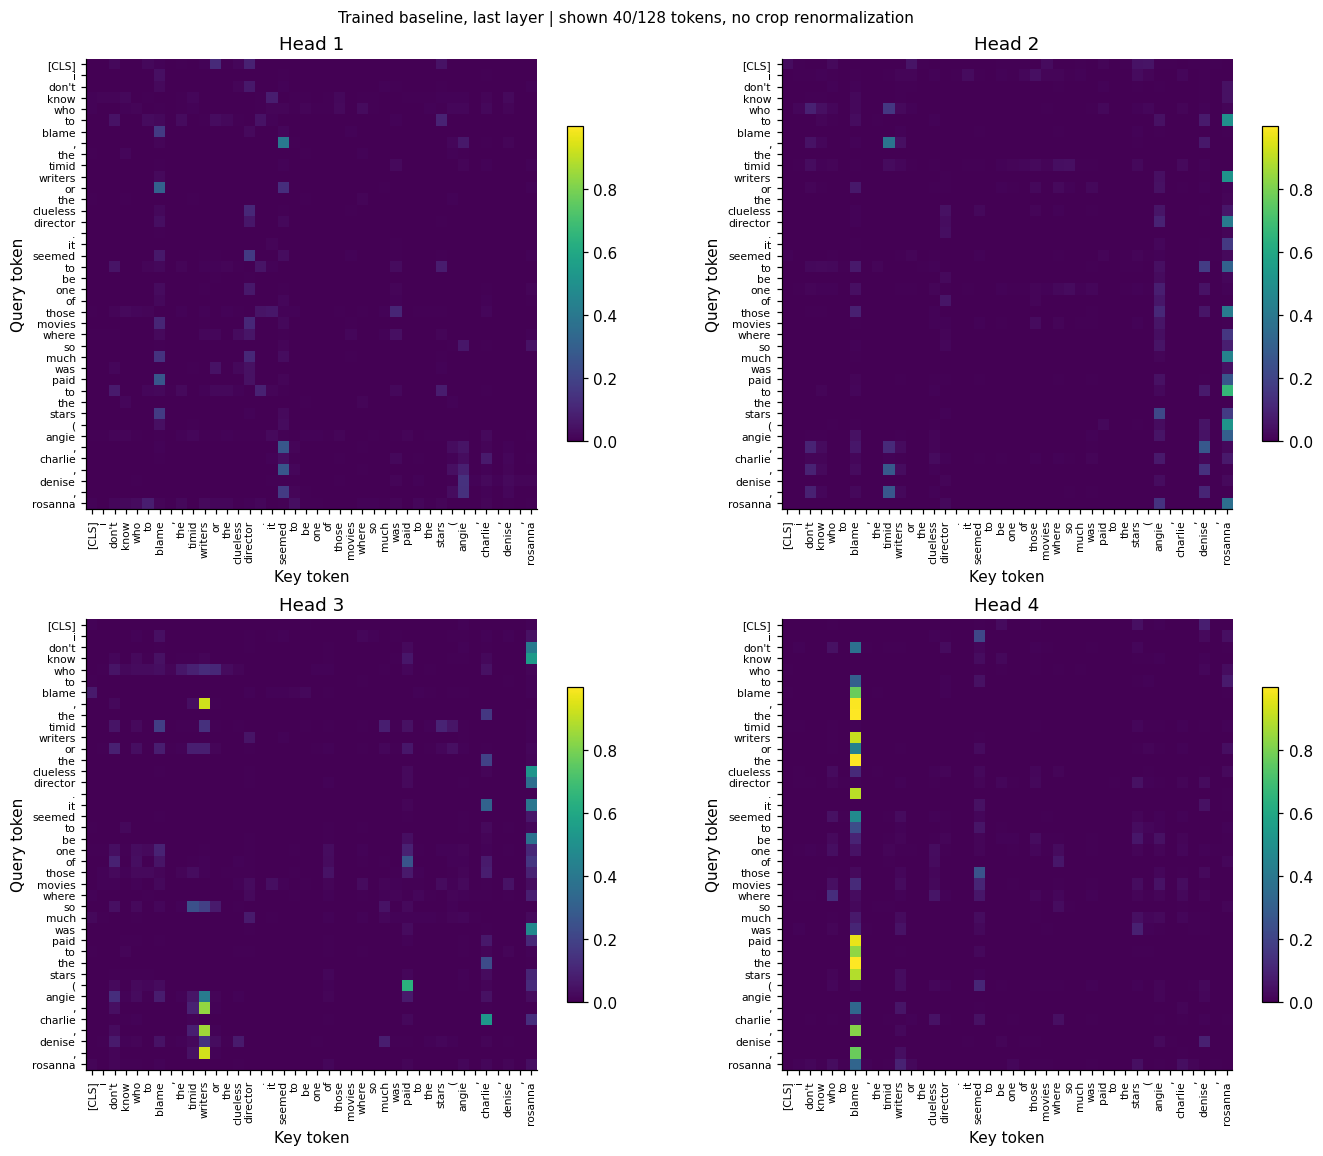

,head,mean_entropy,normalized_entropy,mean_row_max
0,1,2.612159,0.538364,0.379646
1,2,2.564446,0.528531,0.376374
2,3,2.467838,0.508620,0.404758
3,4,2.861026,0.589655,0.350760


,head_a,head_b,mean_row_l1
0,1,2,1.711378
1,1,3,1.717411
2,1,4,1.648918
3,2,3,1.674275
4,2,4,1.644688
5,3,4,1.695951


In [38]:
@torch.no_grad()
def attention_for_text(model, text, max_length):
    tokens = tokenize(text)
    content_ids = [vocab.get(t, UNK_ID) for t in tokens] or [UNK_ID]
    encoded = [CLS_ID] + content_ids[:max_length - 1]
    ids = torch.tensor([encoded], dtype=torch.long, device=DEVICE)
    logits, maps = model(ids, return_attention=True)
    labels = ['[CLS]'] + (tokens or ['[UNK]'])[:max_length - 1]
    return logits.softmax(-1)[0].cpu().numpy(), maps[-1][0].cpu().numpy(), labels


def plot_attention(weights, labels, path, title, max_display=40):
    n_heads, full_length, _ = weights.shape
    shown = min(max_display, full_length)
    columns = min(2, n_heads)
    rows = math.ceil(n_heads / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(6.3*columns, 5.2*rows),
                             squeeze=False, constrained_layout=True)
    vmax = max(float(weights[:, :shown, :shown].max()), 1e-8)
    for h, ax in enumerate(axes.flat):
        if h >= n_heads:
            ax.axis('off')
            continue
        im = ax.imshow(weights[h, :shown, :shown], cmap='viridis', vmin=0, vmax=vmax)
        tick_ids = np.arange(shown)
        ax.set_xticks(tick_ids, labels[:shown], rotation=90, fontsize=7)
        ax.set_yticks(tick_ids, labels[:shown], fontsize=7)
        ax.set(xlabel='Key token', ylabel='Query token', title=f'Head {h+1}')
        fig.colorbar(im, ax=ax, shrink=.7)
    fig.suptitle(f'{title} | shown {shown}/{full_length} tokens, no crop renormalization', fontsize=10)
    fig.savefig(path, dpi=160)
    plt.show()


reference_model = load_model(BASE_RECORD)
HEAD_EXAMPLE_INDEX = 0  # Có thể đổi, nhưng ghi rõ mẫu đã dùng.
head_text = val_df.iloc[HEAD_EXAMPLE_INDEX].text
head_probs, head_weights, head_labels = attention_for_text(reference_model, head_text, BASE_LENGTH)
print('Validation source_id:', val_df.iloc[HEAD_EXAMPLE_INDEX].source_id)
print('p(positive):', float(head_probs[1]))
plot_attention(head_weights, head_labels, ARTIFACT_DIR/'attention_heads.png', 'Trained baseline, last layer')
head_stats = []
for h, weights in enumerate(head_weights):
    entropy = -(weights * np.log(np.clip(weights, 1e-12, 1))).sum(-1)
    head_stats.append(dict(head=h+1, mean_entropy=float(entropy.mean()),
                           normalized_entropy=float(entropy.mean()/max(np.log(len(head_labels)), 1e-12)),
                           mean_row_max=float(weights.max(-1).mean())))
head_stats = pd.DataFrame(head_stats)
head_distances = pd.DataFrame([
    dict(head_a=i+1, head_b=j+1, mean_row_l1=float(np.abs(head_weights[i]-head_weights[j]).sum(-1).mean()))
    for i, j in itertools.combinations(range(len(head_weights)), 2)
])
head_stats.to_csv(ARTIFACT_DIR/'head_diversity.csv', index=False)
head_distances.to_csv(ARTIFACT_DIR/'head_distances.csv', index=False)
display(head_stats)
display(head_distances)


### Kết quả và trả lời câu hỏi — Experiment 3: Attention Head Diversity

**Câu hỏi: Multi-head attention có tạo ra các attention patterns khác nhau trong experiment này không?** **Có khác biệt quan sát được trên mẫu validation đã chọn** (`train/neg/10006_4.txt`, xác suất positive $\approx0.0570$), xét lớp attention cuối cùng của checkpoint Transformer 4 heads đã huấn luyện:

| Head | Entropy chuẩn hóa | Trung bình trọng số lớn nhất mỗi hàng |
|---:|---:|---:|
| 1 | 0.5384 | 0.3796 |
| 2 | 0.5285 | 0.3764 |
| 3 | 0.5086 | 0.4048 |
| 4 | 0.5897 | 0.3508 |

Head 3 có entropy thấp nhất và `mean_row_max` cao nhất, **tương đối tập trung hơn**; head 4 entropy cao nhất và `mean_row_max` thấp nhất, **tương đối phân tán hơn**. Khoảng cách L1 trung bình giữa các cặp head khoảng **1.6447–1.7174**, không bằng 0, cho thấy các ma trận attention không trùng nhau trên ví dụ này.

**Giới hạn diễn giải:** các số trên chỉ mô tả **phân phối trọng số attention** của một review cụ thể, không chứng minh từng head đã học cú pháp, ngữ nghĩa hay nguyên nhân dự đoán. Cũng chưa đủ cơ sở kết luận head nào là *redundant* trên toàn bộ dữ liệu: cần kiểm tra nhiều mẫu/seed và có thể thử ablation head.


## 21. Experiment 4 – Transformer vs RNN/LSTM

So sánh LSTM một tầng và Transformer một block với `d_model=128`, cùng dữ liệu, input có CLS, tokenizer, vocabulary, độ dài, batch size, optimizer, learning rate và số epoch. LSTM dùng final hidden state từ **packed sequence** để bỏ padding; Transformer dùng masked mean pooling. Sự khác nhau về capacity, pooling và architecture cần được nêu trong phân tích.

Không đặt mục tiêu Transformer phải thắng. Đọc và chia IMDb giống W6 (gộp 50.000 review rồi chia group-aware 70/15/15). Nếu so với kết quả LAB 05, cần ghi rõ khác biệt về tokenizer, kích thước mẫu và cấu hình huấn luyện.

In [39]:
comparison_records = []
for seed in SEEDS:
    comparison_records.append(run_experiment(ExperimentSpec(seed=seed)))
    comparison_records.append(run_experiment(ExperimentSpec(model_type='lstm', seed=seed)))
model_comparison = pd.DataFrame(comparison_records)
model_comparison.to_csv(ARTIFACT_DIR/'model_comparison.csv', index=False)
display(model_comparison[['model_type', 'seed', 'parameters', 'train_seconds', 'fit_seconds',
                          'accuracy', 'precision_macro', 'recall_macro', 'f1_macro']])
display(summarize_runs(model_comparison, 'model_type'))


lstm_h4_l128_mean_pe1_s42 | epoch 1/8 | train=0.6431 val=0.5915 F1=0.7043
lstm_h4_l128_mean_pe1_s42 | epoch 2/8 | train=0.4933 val=0.4249 F1=0.8027
lstm_h4_l128_mean_pe1_s42 | epoch 3/8 | train=0.3727 val=0.3845 F1=0.8304
lstm_h4_l128_mean_pe1_s42 | epoch 4/8 | train=0.2996 val=0.4443 F1=0.8352
lstm_h4_l128_mean_pe1_s42 | epoch 5/8 | train=0.2406 val=0.3871 F1=0.8391
lstm_h4_l128_mean_pe1_s42 | epoch 6/8 | train=0.1890 val=0.4457 F1=0.8461
lstm_h4_l128_mean_pe1_s42 | epoch 7/8 | train=0.1458 val=0.4540 F1=0.8475
lstm_h4_l128_mean_pe1_s42 | epoch 8/8 | train=0.1107 val=0.5150 F1=0.8436
lstm_h4_l128_mean_pe1_s52 | epoch 1/8 | train=0.6520 val=0.5382 F1=0.7567
lstm_h4_l128_mean_pe1_s52 | epoch 2/8 | train=0.4291 val=0.3769 F1=0.8305
lstm_h4_l128_mean_pe1_s52 | epoch 3/8 | train=0.3103 val=0.3607 F1=0.8419
lstm_h4_l128_mean_pe1_s52 | epoch 4/8 | train=0.2374 val=0.3901 F1=0.8423
lstm_h4_l128_mean_pe1_s52 | epoch 5/8 | train=0.1783 val=0.4414 F1=0.8469
lstm_h4_l128_mean_pe1_s52 | epoch 6/8 

,model_type,seed,parameters,train_seconds,fit_seconds,accuracy,precision_macro,recall_macro,f1_macro
0,transformer,42,2692738,73.871608,80.281355,0.839712,0.839979,0.839695,0.839676
1,lstm,42,2692354,98.733350,105.997347,0.830911,0.835058,0.830844,0.830366
2,transformer,52,2692738,71.776660,77.933349,0.829444,0.829528,0.829453,0.829436
3,lstm,52,2692354,98.609068,105.836510,0.842112,0.843906,0.842156,0.841918
4,transformer,62,2692738,76.305255,82.755815,0.829844,0.830143,0.829862,0.829811
5,lstm,62,2692354,96.966710,105.901106,0.844246,0.844264,0.844242,0.844243


parameters      fit_seconds         train_seconds          \
                  mean  std        mean     std          mean     std   
model_type                                                              
lstm         2692354.0  0.0    105.9117  0.0809       98.1030  0.9861   
transformer  2692738.0  0.0     80.3235  2.4115       73.9845  2.2664   

            accuracy         precision_macro         recall_macro          \
                mean     std            mean     std         mean     std   
model_type                                                                  
lstm          0.8391  0.0072          0.8411  0.0052       0.8391  0.0072   
transformer   0.8330  0.0058          0.8332  0.0059       0.8330  0.0058   

            f1_macro          
                mean     std  
model_type                    
lstm          0.8388  0.0074  
transformer   0.8330  0.0058

### Kết quả và trả lời câu hỏi — Experiment 4: Transformer vs. LSTM

**Câu hỏi: Sự khác biệt về performance có thể xuất phát từ những thành phần architecture nào?** Hai mô hình được chạy trên cùng dữ liệu/validation split và cấu hình so sánh; kết quả **trung bình 3 seed**:

| Mô hình | Tham số | Accuracy | F1 macro | Train time TB (giây) | Fit time TB (giây) |
|---|---:|---:|---:|---:|---:|
| Transformer | 2.692.738 | 0.8330 | 0.8330 | 73.98 | 80.32 |
| LSTM | 2.692.354 | 0.8391 | 0.8388 | 98.10 | 105.91 |

Trên kết quả đã chạy, **LSTM nhỉnh hơn khoảng 0.0059 F1**, trong khi **Transformer train nhanh hơn khoảng 24 giây/run**, tức khoảng 25% thời gian train của LSTM trong thiết lập này. Ở seed 42, Transformer lại tốt hơn LSTM về F1 (0.8397 so với 0.8304); do vậy thứ hạng có dao động theo seed.

Lời giải thích ở mức giả thuyết kiến trúc: LSTM cập nhật trạng thái tuần tự với cơ chế gate, còn Transformer dùng self-attention để các token tương tác trực tiếp, kèm positional encoding và FFN; khả năng song song hóa có thể đóng góp vào tốc độ trên GPU. Tuy nhiên **không thể quy toàn bộ chênh lệch F1/thời gian cho riêng một thành phần** khi chưa ablation và chưa benchmark đa phần cứng. Thực nghiệm **không cho thấy Transformer luôn chính xác hơn LSTM**.


## 22. Experiment 5 – sequence length

**Biến thay đổi:** `max_length=32,64,128,256`, gồm CLS; content budget là `max_length-1`. Giữ 4 heads và các yếu tố còn lại. Pad đến đúng chiều dài cấu hình để chi phí attention so sánh được.

`tokens_retained_*` là tỷ lệ **content tokens**, không tính CLS/padding. `truncated_*` là tỷ lệ review bị cắt. `score_matrix_mib` là **ước lượng một tensor score float32 cho một layer, một batch cấu hình**: $BHT^2\times4/2^{20}$ MiB. Đây không phải tổng RAM/VRAM training. `peak_cuda_mib` là bộ nhớ CUDA allocated cao nhất quan sát trong fit; CPU để trống.


transformer_h4_l32_mean_pe1_s42 | epoch 1/8 | train=0.6181 val=0.5724 F1=0.6869
transformer_h4_l32_mean_pe1_s42 | epoch 2/8 | train=0.5437 val=0.5381 F1=0.7175
transformer_h4_l32_mean_pe1_s42 | epoch 3/8 | train=0.4932 val=0.5313 F1=0.7267
transformer_h4_l32_mean_pe1_s42 | epoch 4/8 | train=0.4472 val=0.5440 F1=0.7334
transformer_h4_l32_mean_pe1_s42 | epoch 5/8 | train=0.4074 val=0.5816 F1=0.7323
transformer_h4_l32_mean_pe1_s42 | epoch 6/8 | train=0.3744 val=0.5752 F1=0.7342
transformer_h4_l32_mean_pe1_s42 | epoch 7/8 | train=0.3415 val=0.6013 F1=0.7351
transformer_h4_l32_mean_pe1_s42 | epoch 8/8 | train=0.3174 val=0.6049 F1=0.7383
transformer_h4_l64_mean_pe1_s42 | epoch 1/8 | train=0.5750 val=0.5043 F1=0.7480
transformer_h4_l64_mean_pe1_s42 | epoch 2/8 | train=0.4707 val=0.4739 F1=0.7771
transformer_h4_l64_mean_pe1_s42 | epoch 3/8 | train=0.4063 val=0.4494 F1=0.7919
transformer_h4_l64_mean_pe1_s42 | epoch 4/8 | train=0.3554 val=0.4672 F1=0.7877
transformer_h4_l64_mean_pe1_s42 | epoch 

,seed,max_length,tokens_retained_train,tokens_retained_validation,truncated_validation,score_matrix_mib,peak_cuda_mib,train_seconds,fit_seconds,f1_macro
0,42,32,0.116188,0.116310,0.997866,0.5,90.010254,67.655968,73.146939,0.726725
1,42,64,0.234792,0.234926,0.965595,2.0,91.982910,67.484618,73.098451,0.791948
2,42,128,0.453815,0.454606,0.849047,8.0,112.481934,73.871608,80.281355,0.839676
3,42,256,0.721270,0.724496,0.356181,32.0,218.963379,116.514046,126.796749,0.876650
4,52,32,0.116188,0.116310,0.997866,0.5,90.010254,66.557459,71.821354,0.713442
5,52,64,0.234792,0.234926,0.965595,2.0,91.982910,66.470033,72.017270,0.778610
6,52,128,0.453815,0.454606,0.849047,8.0,112.372559,71.776660,77.933349,0.829436
7,52,256,0.721270,0.724496,0.356181,32.0,218.963379,116.487672,127.039235,0.864823
8,62,32,0.116188,0.116310,0.997866,0.5,90.010254,67.000830,72.625242,0.732368
9,62,64,0.234792,0.234926,0.965595,2.0,91.982910,67.427549,72.931300,0.785960


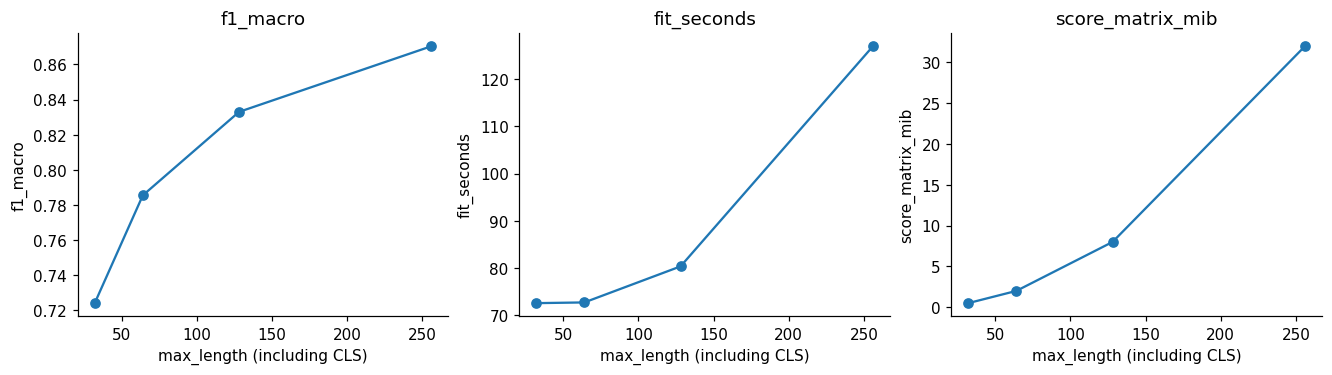

In [40]:
def retention_stats(items, max_length):
    lengths = np.array([x['token_count'] for x in items], dtype=np.int64)
    kept = np.minimum(lengths, max_length-1)
    return float(kept.sum()/max(lengths.sum(), 1)), float(np.mean(lengths > max_length-1))


length_records = []
for seed in SEEDS:
    for length in [32, 64, 128, 256]:
        record = dict(run_experiment(ExperimentSpec(max_length=length, seed=seed)))
        record['tokens_retained_train'], record['truncated_train'] = retention_stats(train_items, length)
        record['tokens_retained_validation'], record['truncated_validation'] = retention_stats(val_items, length)
        record['score_matrix_mib'] = BATCH_SIZE * BASE_HEADS * length**2 * 4 / 2**20
        length_records.append(record)
sequence_length_results = pd.DataFrame(length_records)
sequence_length_results.to_csv(ARTIFACT_DIR/'sequence_length_results.csv', index=False)
display(sequence_length_results[['seed', 'max_length', 'tokens_retained_train',
                                 'tokens_retained_validation', 'truncated_validation',
                                 'score_matrix_mib', 'peak_cuda_mib', 'train_seconds',
                                 'fit_seconds', 'f1_macro']])
length_summary = sequence_length_results.groupby('max_length')[['f1_macro', 'fit_seconds', 'score_matrix_mib']].mean()
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), constrained_layout=True)
for ax, column in zip(axes, length_summary.columns):
    ax.plot(length_summary.index, length_summary[column], 'o-')
    ax.set(xlabel='max_length (including CLS)', ylabel=column, title=column)
fig.savefig(ARTIFACT_DIR/'sequence_length.png', dpi=180)
plt.show()


### Kết quả và trả lời câu hỏi — Experiment 5: Sequence Length

**Câu hỏi: Tại sao Transformer không đơn giản giải quyết mọi vấn đề bằng cách tăng sequence length?** Kết quả chạy `max_length = 32, 64, 128, 256` với 4 heads, `d_model=128`, batch size 32, cùng 3 seed:

| `max_length` (gồm CLS) | Tỷ lệ token validation giữ lại | Tỷ lệ review validation bị cắt | F1 macro TB | Attention score matrix (MiB) | Train time TB (giây) |
|---:|---:|---:|---:|---:|---:|
| 32 | 11.63% | 99.79% | 0.7242 | 0.5 | 67.07 |
| 64 | 23.49% | 96.56% | 0.7855 | 2.0 | 67.13 |
| 128 | 45.46% | 84.90% | 0.8330 | 8.0 | 73.98 |
| 256 | 72.45% | 35.62% | 0.8703 | 32.0 | 116.60 |

Trong dữ liệu IMDb của lần chạy này, giữ lại nhiều review hơn giúp F1 tăng. Nhưng self-attention dày tạo ma trận điểm số dạng $T\times T$, nên bộ nhớ cho riêng một attention score matrix tăng theo $O(T^2)$: **32 → 256 token (dài gấp 8) làm phần này tăng 64 lần**, từ 0.5 lên 32 MiB. Thời gian train trung bình cũng tăng khoảng **1.74 lần** (67.07 → 116.60 giây); peak CUDA memory trong output tăng khoảng **90 → 219 MiB**. Số liệu matrix (MiB) là **ước lượng tensor score** theo công thức trong code, không phải toàn bộ VRAM.

Ngay cả tại 256, còn khoảng **35.62% review validation bị truncation**. Vì vậy tăng độ dài không thể mãi là cách giải duy nhất: nó tốn GPU RAM, thời gian và vẫn có giới hạn context. Có thể cần lựa chọn chiều dài phù hợp, mô hình long-context hoặc chiến lược chia/nhận diện thông tin trọng tâm tùy yêu cầu.


## 23. Application — Transformer text classification

**Pipeline:** raw text → tokenizer → token IDs → embedding → PE → Transformer Encoder → masked mean pooling → linear classifier → softmax.

Ứng dụng dùng checkpoint chính đã cố định. Test ít nhất 5 nhóm: **câu ngắn, câu dài, negation, contrast, ambiguous sentiment**. Câu ambiguous không ép một nhãn đúng duy nhất; đây là probe để quan sát hành vi, không phải bộ test có gold labels. Xác suất softmax chưa được hiệu chỉnh, không đồng nghĩa xác suất dự đoán đúng.

Câu dài được đặt tín hiệu khác nhau ở đầu/cuối để dễ kiểm tra truncation. `visible_input` cho biết chính xác phần văn bản model nhìn thấy.


In [41]:
@torch.no_grad()
def predict_texts(model, texts, max_length=BASE_LENGTH):
    model.eval()
    rows = []
    for text in texts:
        tokens = tokenize(text)
        full_ids = [vocab.get(t, UNK_ID) for t in tokens] or [UNK_ID]
        kept_ids = full_ids[:max_length-1]
        ids = torch.tensor([[CLS_ID] + kept_ids], dtype=torch.long, device=DEVICE)
        logits, _ = model(ids)
        probs = logits.softmax(-1)[0].cpu().numpy()
        pred = int(probs.argmax())
        visible_tokens = (tokens or ['[UNK]'])[:max_length-1]
        rows.append(dict(text=text, predicted_label=LABEL_NAMES[pred],
                         p_negative=float(probs[0]), p_positive=float(probs[1]),
                         predicted_probability=float(probs[pred]),
                         total_content_tokens=len(tokens), retained_content_tokens=len(visible_tokens),
                         truncated=len(tokens) > max_length-1,
                         unknown_rate=kept_ids.count(UNK_ID)/max(len(kept_ids), 1),
                         visible_input=' '.join(visible_tokens)))
    return pd.DataFrame(rows)


APP_CASES = [
    ('short', 'I really enjoyed this movie.'),
    ('long', 'At first I thought this was an excellent movie. ' +
     'The characters discuss their journey and the story continues through many scenes. ' * 22 +
     'However, the ending was terrible and I would not recommend it.'),
    ('negation', 'I did not enjoy this movie, and it was not good.'),
    ('contrast', 'The acting was excellent, but the story was boring and disappointing.'),
    ('ambiguous', 'Some moments were good, some were bad, and I am still unsure about this movie.'),
]
application_results = predict_texts(reference_model, [text for _, text in APP_CASES])
application_results.insert(0, 'case', [name for name, _ in APP_CASES])
application_results.to_csv(ARTIFACT_DIR/'application_predictions.csv', index=False)
with pd.option_context('display.max_colwidth', 120):
    display(application_results[['case', 'text', 'predicted_label', 'p_negative', 'p_positive',
                                 'total_content_tokens', 'retained_content_tokens', 'truncated']])
# Thử câu của bạn sau khi model đã được train:
# display(predict_texts(reference_model, ['Your own review here.']))


,case,text,predicted_label,p_negative,p_positive,total_content_tokens,retained_content_tokens,truncated
0,short,I really enjoyed this movie.,positive,0.133621,0.866379,6,6,False
1,long,At first I thought this was an excellent movie. The characters discuss their journey and the story continues through...,positive,0.000960,0.999040,309,127,True
2,negation,"I did not enjoy this movie, and it was not good.",positive,0.089650,0.910350,13,13,False
3,contrast,"The acting was excellent, but the story was boring and disappointing.",negative,0.990858,0.009142,13,13,False
4,ambiguous,"Some moments were good, some were bad, and I am still unsure about this movie.",negative,0.999213,0.000787,18,18,False


### Đọc kết quả kiểm thử 5 loại câu — Application

Output hiện có cho model cuối cùng (4 heads, length 128, mean pooling, seed 42):

| Kiểu câu | Dự đoán thực tế | P(positive) | Nhận xét có căn cứ |
|---|---|---:|---|
| Short | Positive | 0.8664 | Phù hợp với câu khen phim ngắn. |
| Long | Positive | 0.9990 | **309 content tokens nhưng chỉ giữ 127**; phần đánh giá tiêu cực cuối văn bản bị cắt, nên xác suất này không phản ánh việc mô hình đã đọc toàn câu. |
| Negation | Positive | 0.9104 | **Sai đối với câu phủ định rõ ràng** “I did not enjoy ... not good”; đây là dấu hiệu mô hình còn yếu ở tình huống phủ định. |
| Contrast | Negative | 0.0091 | Phù hợp với đoạn chê câu chuyện dù khen diễn xuất. |
| Ambiguous | Negative | 0.0008 | Mô hình rất tự tin với câu pha trộn tích cực/tiêu cực; không nên hiểu xác suất cao là dự đoán chắc chắn đúng khi nhãn vốn mơ hồ. |

Đây chỉ là năm câu **kiểm thử minh họa**, không có nhãn gold do một tập đánh giá độc lập cung cấp. Vì vậy nhận xét đúng/sai ở đây dựa trên cách đọc nội dung câu, **không** được dùng để tính Accuracy hay F1. Muốn xác nhận nguyên nhân của lỗi negation/truncation cần thêm cặp câu đối chứng hoặc đánh giá có nhãn.


## 24. Pooling

Transformer trả một vector tại mỗi token. `masked_mean` bên trên chỉ lấy trung bình **content tokens hợp lệ**, bỏ `[PAD]` và `[CLS]`. CLS vẫn tham gia attention ở cả hai model của experiment tiếp theo, do đó khác biệt được khảo sát là cách lấy sequence representation.

CLS-style ở đây là một token học từ đầu cùng classifier, không phải CLS pretrained của BERT.


## 25. Experiment 6 – pooling strategy

**Biến thay đổi:** mean / CLS-style. Cùng input `[CLS] + content`, PE, block, 4 heads và chiều dài 128. Hai model được **huấn luyện riêng**; không đổi pooling trên cùng một checkpoint đã train rồi coi là so sánh công bằng.


In [42]:
pooling_records = []
for seed in SEEDS:
    for pooling in ['mean', 'cls']:
        pooling_records.append(run_experiment(ExperimentSpec(pooling=pooling, seed=seed)))
pooling_results = pd.DataFrame(pooling_records)
pooling_results.to_csv(ARTIFACT_DIR/'pooling_results.csv', index=False)
display(pooling_results[['seed', 'pooling', 'accuracy', 'f1_macro', 'train_seconds', 'fit_seconds']])
display(summarize_runs(pooling_results, 'pooling'))


transformer_h4_l128_cls_pe1_s42 | epoch 1/8 | train=0.5758 val=0.5101 F1=0.7447
transformer_h4_l128_cls_pe1_s42 | epoch 2/8 | train=0.5004 val=0.4689 F1=0.7730
transformer_h4_l128_cls_pe1_s42 | epoch 3/8 | train=0.4538 val=0.4535 F1=0.7858
transformer_h4_l128_cls_pe1_s42 | epoch 4/8 | train=0.4035 val=0.4079 F1=0.8181
transformer_h4_l128_cls_pe1_s42 | epoch 5/8 | train=0.3575 val=0.4069 F1=0.8256
transformer_h4_l128_cls_pe1_s42 | epoch 6/8 | train=0.3202 val=0.3830 F1=0.8334
transformer_h4_l128_cls_pe1_s42 | epoch 7/8 | train=0.2905 val=0.3680 F1=0.8361
transformer_h4_l128_cls_pe1_s42 | epoch 8/8 | train=0.2615 val=0.3667 F1=0.8438
transformer_h4_l128_cls_pe1_s52 | epoch 1/8 | train=0.5922 val=0.5201 F1=0.7414
transformer_h4_l128_cls_pe1_s52 | epoch 2/8 | train=0.5054 val=0.4699 F1=0.7747
transformer_h4_l128_cls_pe1_s52 | epoch 3/8 | train=0.4561 val=0.4364 F1=0.8000
transformer_h4_l128_cls_pe1_s52 | epoch 4/8 | train=0.4045 val=0.3918 F1=0.8274
transformer_h4_l128_cls_pe1_s52 | epoch 

,seed,pooling,accuracy,f1_macro,train_seconds,fit_seconds
0,42,mean,0.839712,0.839676,73.871608,80.281355
1,42,cls,0.843846,0.843752,69.416908,75.559547
2,52,mean,0.829444,0.829436,71.776660,77.933349
3,52,cls,0.823576,0.822922,69.584725,75.774865
4,62,mean,0.829844,0.829811,76.305255,82.755815
5,62,cls,0.835045,0.834943,72.551309,79.497045


parameters      fit_seconds         train_seconds         accuracy  \
              mean  std        mean     std          mean     std     mean   
pooling                                                                      
cls      2692738.0  0.0     76.9438  2.2138       70.5176  1.7632   0.8342   
mean     2692738.0  0.0     80.3235  2.4115       73.9845  2.2664   0.8330   

                precision_macro         recall_macro         f1_macro          
            std            mean     std         mean     std     mean     std  
pooling                                                                        
cls      0.0102          0.8362  0.0082       0.8341  0.0102   0.8339  0.0105  
mean     0.0058          0.8332  0.0059       0.8330  0.0058   0.8330  0.0058

### Kết quả và trả lời câu hỏi — Experiment 6: Pooling Strategy

**Câu hỏi: Cách lấy sequence representation có ảnh hưởng tới classification không?** Có ảnh hưởng **trong một số run**, nhưng khác biệt trung bình khá nhỏ. Hai cách đều được **train riêng** với input `[CLS] + content` và **cùng 2.692.738 tham số**:

| Pooling | F1 macro seed 42 | Seed 52 | Seed 62 | F1 macro trung bình | Accuracy trung bình |
|---|---:|---:|---:|---:|---:|
| Masked mean | 0.8397 | 0.8294 | 0.8298 | 0.8330 | 0.8330 |
| CLS-style | 0.8438 | 0.8229 | 0.8349 | 0.8339 | 0.8342 |

CLS-style cao hơn mean khoảng **0.0009 F1 macro trung bình**, nhưng **seed 52 thì kém hơn** (0.8229 so với 0.8294). Vì vậy thí nghiệm chứng minh lựa chọn pooling **có thể làm đổi kết quả**, không đủ bằng chứng kết luận CLS-style luôn tốt hơn mean pooling. Đây là mô hình huấn luyện từ đầu với first-token/CLS-style, **không phải** `[CLS]` pretrained của BERT.


### Đánh giá test cuối cùng cho model chính

Giữ nguyên `BASE_SPEC` đã chốt trước thí nghiệm. Test được dùng để báo cáo kết quả cuối và chọn mẫu phân tích, không dùng để chọn heads/length/pooling. Tên split được ghi rõ trong file kết quả.


,run_id,split,profile,n_test,loss,accuracy,precision_macro,recall_macro,f1_macro,f1_positive
0,transformer_h4_l128_mean_pe1_s42,test,full,7502,0.372796,0.835111,0.83521,0.835115,0.8351,0.836441


              precision    recall  f1-score   support

    negative       0.84      0.83      0.83      3753
    positive       0.83      0.84      0.84      3749

    accuracy                           0.84      7502
   macro avg       0.84      0.84      0.84      7502
weighted avg       0.84      0.84      0.84      7502



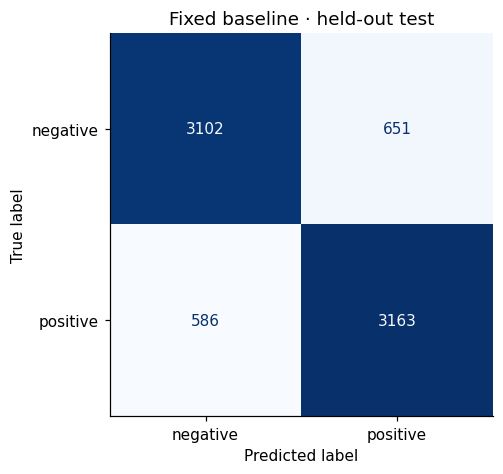

In [43]:
final_model = reference_model  # Model chính: h4, length128, mean; seed đầu tiên.
test_metrics, test_predictions = evaluate(final_model, make_loader(test_items, BASE_LENGTH))
test_predictions.insert(0, 'source_id', test_df.source_id.tolist())
test_predictions['text'] = test_df.text.tolist()
test_predictions['total_content_tokens'] = [x['token_count'] for x in test_items]
test_predictions['retained_content_tokens'] = [min(x['token_count'], BASE_LENGTH-1) for x in test_items]
test_predictions['truncated'] = test_predictions.total_content_tokens > BASE_LENGTH-1
test_predictions['unknown_rate_visible'] = [
    item['ids'][:BASE_LENGTH-1].count(UNK_ID)/max(len(item['ids'][:BASE_LENGTH-1]), 1)
    for item in test_items
]
test_predictions.to_csv(ARTIFACT_DIR/'test_predictions.csv', index=False)
final_result = dict(run_id=BASE_RECORD['run_id'], split='test', profile=PROFILE,
                    n_test=len(test_items), **test_metrics)
pd.DataFrame([final_result]).to_csv(ARTIFACT_DIR/'final_test_metrics.csv', index=False)
display(pd.DataFrame([final_result]))
print(classification_report(test_predictions.y_true, test_predictions.y_pred,
                            labels=[0, 1], target_names=LABEL_NAMES, zero_division=0))
fig, ax = plt.subplots(figsize=(4.8, 4.2), constrained_layout=True)
ConfusionMatrixDisplay(confusion_matrix(test_predictions.y_true, test_predictions.y_pred, labels=[0,1]),
                       display_labels=LABEL_NAMES).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Fixed baseline · held-out test')
fig.savefig(ARTIFACT_DIR/'confusion_matrix.png', dpi=180)
plt.show()


### Đánh giá cuối cùng trên test

Checkpoint chính `transformer_h4_l128_mean_pe1_s42` được đánh giá trên **7.502 review test** theo cách chia lại W6; kết quả output: **Accuracy = 0.8351**, **Macro Precision = 0.8352**, **Macro Recall = 0.8351**, **Macro F1 = 0.8351**. Tập test chứa **3.753 review negative** và **3.749 review positive**. Các số này là **test metrics của một checkpoint cố định (seed 42)**; không đồng nhất với kết quả F1 trung bình validation của 3 seed ở các experiment phía trên.

Lưu ý: `source_id` còn tiền tố `train/` hoặc `test/` để chỉ **thư mục IMDb gốc**. Sau khi gộp và chia lại như W6, tiền tố này **không còn chỉ tập train/test hiện tại**; cột `split` và `split_manifest.csv` mới ghi nhận phân chia dùng trong experiment.


## 26. Error analysis — chọn các dự đoán sai

Cell dưới chỉ lọc các trường hợp **dự đoán sai** trên tập test và hiển thị những ví dụ có độ tự tin cao nhất; toàn bộ các trường hợp sai được lưu vào `artifacts/incorrect_predictions.csv` để phân tích riêng trong `error_analysis.md`. Cell không tự tạo câu trả lời, không vẽ attention cho từng lỗi và không ghi đè file phân tích riêng.

Các ví dụ có thể thuộc thư mục `train/` của IMDb gốc do quy trình **gộp 50.000 review rồi chia lại theo W6**. Hãy dùng split test hiện tại (`test_predictions`), không suy từ tiền tố `source_id`.


In [47]:
# Chỉ hiển thị những dự đoán sai; đổi số này nếu muốn xem nhiều hơn.
N_ERRORS_TO_SHOW = 3

wrong_predictions = test_predictions.loc[
    test_predictions['y_true'] != test_predictions['y_pred']
].copy()
wrong_predictions['gold_label'] = wrong_predictions['y_true'].map({0: 'negative', 1: 'positive'})
wrong_predictions['predicted_label'] = wrong_predictions['y_pred'].map({0: 'negative', 1: 'positive'})
wrong_predictions['predicted_confidence'] = np.where(
    wrong_predictions['y_pred'].eq(1),
    wrong_predictions['p_positive'],
    1.0 - wrong_predictions['p_positive'],
)
wrong_predictions = wrong_predictions.sort_values(
    'predicted_confidence', ascending=False
).reset_index(drop=True)

# Lưu TẤT CẢ các lỗi, gồm văn bản đầy đủ, để tự viết error_analysis.md sau.
wrong_predictions.to_csv(ARTIFACT_DIR / 'incorrect_predictions.csv', index=False)
print(f'Dự đoán sai: {len(wrong_predictions)}/{len(test_predictions)} mẫu test')
print('Toàn bộ mẫu sai: artifacts/incorrect_predictions.csv')

if wrong_predictions.empty:
    print('Không có mẫu dự đoán sai trên tập test này.')
else:
    examples = wrong_predictions.head(N_ERRORS_TO_SHOW).copy()
    examples.insert(0, 'case_id', [f'error_{i + 1:02d}' for i in range(len(examples))])
    with pd.option_context('display.max_colwidth', None):
        display(examples[[
            'case_id', 'source_id', 'text', 'gold_label', 'predicted_label',
            'p_positive', 'predicted_confidence', 'total_content_tokens',
            'retained_content_tokens', 'truncated', 'unknown_rate_visible',
        ]])


Dự đoán sai: 1237/7502 mẫu test
Toàn bộ mẫu sai: artifacts/incorrect_predictions.csv


,case_id,source_id,text,gold_label,predicted_label,p_positive,predicted_confidence,total_content_tokens,retained_content_tokens,truncated,unknown_rate_visible
0,error_01,train/pos/4185_8.txt,"This movie has everything that makes a bad movie worth watching - sloppy editing, little to no continuity, insane dialog, bad (you might even say non-existent) acting, pointless story lines, shots that go on FAR too long...and it's perfect for MST3K-style riffing, not to mention the ""Corpse Eaters Drinking Game"": Scribble on forms...take a shot - Sign your name...take a shot - Catch a bad Foley edit...take many, many shots.<br /><br />The only reason I didn't rate it higher than 8 is because there's not enough gratuitous nudity and because despite its insane badness, it's only an hour long - hell, a movie like this should have been at least 20-30 minutes longer!",positive,negative,0.001698,0.998302,150,127,True,0.015748
1,error_02,test/neg/7098_1.txt,"This has to be one of, if not THE greatest Mob/Crime films of all time. Every thing about this movie is great, the acting in this film is of true quality; Master P's acting skills make you actually believe he is Italian! The cinematography is excellent too, probably the best ever. This movie was great; and I have the brain capacity of an earth worm.",negative,positive,0.996841,0.996841,76,76,False,0.013158
2,error_03,train/pos/9860_7.txt,"This movie had no parts that were hilarious, mostly just average funny units, but it did not have any parts that were really bad either. The worst part was the voice of Sid. His slothy slur was just too much for me. By about 5 minutes in I was sick of hearing him talk. Aside from the annoying sloth voice the movie was good. There were numerous side jokes which if you catch them make the movie much better. This is a good movie for kids. It has enough in it to keep adults content and enough in it to entertain kids. This one is definitely worth renting if you have kids and want to watch a movie with them.",positive,negative,0.003946,0.996054,131,127,True,0.015748


## 29. Learning curves

Vẽ training loss và validation loss theo từng epoch của **toàn bộ quá trình fit**, trước khi khôi phục best checkpoint. F1 validation được vẽ riêng. Mốc đứt là best epoch theo validation loss. History của mọi run được lưu trong `artifacts/histories/`.


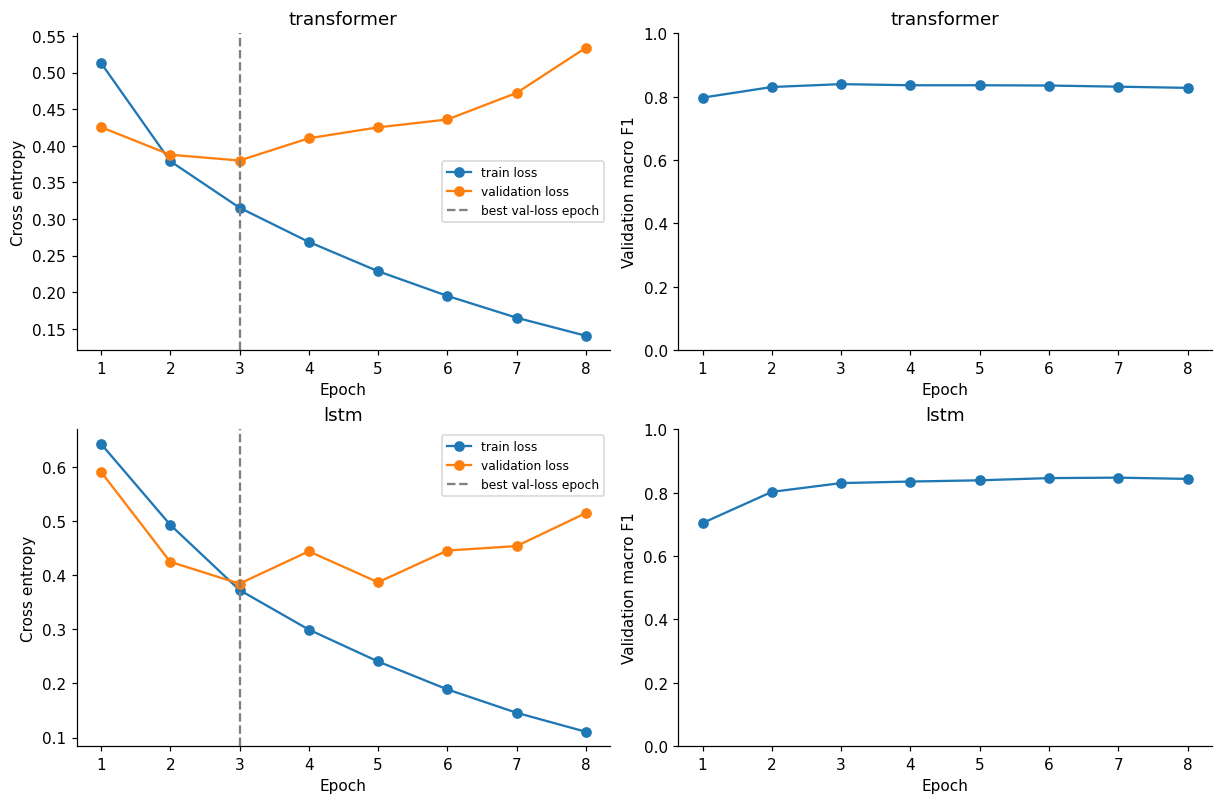

In [45]:
curve_records = [BASE_RECORD, RUN_REGISTRY[ExperimentSpec(model_type='lstm', seed=SEEDS[0])]]
fig, axes = plt.subplots(len(curve_records), 2, figsize=(11, 3.6*len(curve_records)),
                         squeeze=False, constrained_layout=True)
for row_index, record in enumerate(curve_records):
    history = pd.read_csv(ARTIFACT_DIR/'histories'/f'{record["run_id"]}.csv')
    ax = axes[row_index, 0]
    ax.plot(history.epoch, history.train_loss, 'o-', label='train loss')
    ax.plot(history.epoch, history.val_loss, 'o-', label='validation loss')
    ax.axvline(record['best_epoch'], ls='--', color='gray', label='best val-loss epoch')
    ax.set(xlabel='Epoch', ylabel='Cross entropy', title=record['model_type'])
    ax.legend(fontsize=8)
    axes[row_index, 1].plot(history.epoch, history.val_f1_macro, 'o-')
    axes[row_index, 1].set(xlabel='Epoch', ylabel='Validation macro F1', ylim=(0, 1),
                            title=record['model_type'])
fig.savefig(ARTIFACT_DIR/'learning_curves.png', dpi=180)
plt.show()


### Nhận xét từ learning curves đã chạy

Ở **Transformer baseline (seed 42)**, train loss giảm từ **0.5133 (epoch 1)** xuống **0.1403 (epoch 8)**, trong khi validation loss đạt thấp nhất **0.3798 ở epoch 3** rồi tăng lên **0.5339 ở epoch 8**. Validation F1 cũng đạt **0.8397 ở epoch 3** trước khi giảm về **0.8279 ở epoch 8**. Đây là dấu hiệu **overfitting sau các epoch đầu** trong run này, dù train loss vẫn tiếp tục giảm.

Ở **LSTM (seed 42)**, train loss giảm **0.6431 → 0.1107**; validation loss thấp nhất **0.3845 ở epoch 3** và tăng lên **0.5150 ở epoch 8**. Validation F1 có lúc tiếp tục tăng sau epoch 3, vì F1 và cross-entropy đo hai khía cạnh khác nhau. Pipeline chọn **best checkpoint theo validation loss**, không tự động chọn epoch có F1 cao nhất. Cần lưu ý khi so sánh kết quả giữa các mô hình.


## Xuất kết quả và kiểm tra file

Notebook chỉ chứa phần triển khai và thực nghiệm. Bài giải tính toán, prediction, error analysis và reflection được quản lý trong các file riêng: `calculations.md`, `prediction.md`, `error_analysis.md`, `reflection.md`.

Các đầu ra chính gồm `results.csv`, bảng so sánh mô hình, attention heatmaps, learning curves, confusion matrix và kết quả đánh giá. Cell tiếp theo kiểm tra những file đã được tạo sau khi chạy notebook.

In [ ]:
# Kiểm tra đầu ra chính sau khi chạy notebook; file error_analysis.md được viết riêng.
expected_outputs = [
    'results.csv', 'heads_results.csv', 'head_diversity.csv', 'head_distances.csv',
    'model_comparison.csv', 'sequence_length_results.csv', 'pooling_results.csv',
    'final_test_metrics.csv', 'application_predictions.csv',
    'incorrect_predictions.csv', 'permutation_results.csv',
    'positional_encoding.png', 'attention_heads.png', 'sequence_length.png',
    'learning_curves.png', 'confusion_matrix.png', 'split_manifest.csv',
    'vocab.json', 'run_config.json',
]
output_status = pd.DataFrame([
    dict(file=name, exists=(ARTIFACT_DIR / name).is_file(),
         bytes=(ARTIFACT_DIR / name).stat().st_size if (ARTIFACT_DIR / name).is_file() else 0)
    for name in expected_outputs
])
display(output_status)
missing = output_status.loc[~output_status['exists'], 'file'].tolist()
if missing:
    print('Chưa tìm thấy (cần Run All / kiểm tra dữ liệu):', ', '.join(missing))
else:
    print('Đã tìm thấy đủ các artifact tự tạo trong notebook.')
print('error_analysis.md và các file tính toán/prediction/reflection được làm riêng.')
